In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ddosad/datacamps-data-science-associate-certification/fitness_class_2212.csv


# The Data

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/datasets/ddosad/datacamps-data-science-associate-certification/fitness_class_2212.csv')

In [4]:
df.head()

,booking_id,months_as_member,weight,days_before,day_of_week,time,category,attended
0,1,17,79.56,8,Wed,PM,Strength,0
1,2,10,79.01,2,Mon,AM,HIIT,0
2,3,16,74.53,14,Sun,AM,Strength,0
3,4,5,86.12,10,Fri,AM,Cycling,0
4,5,15,69.29,8,Thu,AM,HIIT,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   booking_id        1500 non-null   int64  
 1   months_as_member  1500 non-null   int64  
 2   weight            1480 non-null   float64
 3   days_before       1500 non-null   object 
 4   day_of_week       1500 non-null   object 
 5   time              1500 non-null   object 
 6   category          1500 non-null   object 
 7   attended          1500 non-null   int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 93.9+ KB


In [6]:
df.isnull().sum()

booking_id           0
months_as_member     0
weight              20
days_before          0
day_of_week          0
time                 0
category             0
attended             0
dtype: int64

In [7]:
df.describe()

,booking_id,months_as_member,weight,attended
count,1500.000000,1500.000000,1480.000000,1500.000000
mean,750.500000,15.628667,82.610378,0.302667
std,433.157015,12.926543,12.765859,0.459565
min,1.000000,1.000000,55.410000,0.000000
25%,375.750000,8.000000,73.490000,0.000000
50%,750.500000,12.000000,80.760000,0.000000
75%,1125.250000,19.000000,89.520000,1.000000
max,1500.000000,148.000000,170.520000,1.000000


In [8]:
df.shape

(1500, 8)

In [9]:
df.columns

Index(['booking_id', 'months_as_member', 'weight', 'days_before',
       'day_of_week', 'time', 'category', 'attended'],
      dtype='object')

In [10]:
df['attended'].unique()

array([0, 1])

In [11]:
df['attended'].value_counts(normalize=True)

attended
0    0.697333
1    0.302667
Name: proportion, dtype: float64

In [12]:
df['category'].value_counts()

category
HIIT        667
Cycling     376
Strength    233
Yoga        135
Aqua         76
-            13
Name: count, dtype: int64

In [13]:
df['category'] = df['category'].replace('-','unknown')

In [14]:
df['days_before'].unique()

array(['8', '2', '14', '10', '6', '4', '9', '12', '5', '3', '7', '13',
       '12 days', '20', '1', '15', '6 days', '11', '13 days', '3 days',
       '16', '1 days', '7 days', '8 days', '10 days', '14 days', '17',
       '5 days', '2 days', '4 days', '29'], dtype=object)

In [15]:
df['days_before'] = (
    df['days_before'].astype(str).str.extract(r'(\d+)',expand=False)
)
df['days_before'] = pd.to_numeric(df['days_before'])

In [16]:
print(df['days_before'].isna().sum())
df['days_before'] = df['days_before'].fillna(df['days_before'].median())
df['days_before'] = df['days_before'].astype(int)

0


In [17]:
print(df['days_before'].dtype)
print(df['days_before'].describe())

int64
count    1500.000000
mean        8.346667
std         4.077938
min         1.000000
25%         4.000000
50%         9.000000
75%        12.000000
max        29.000000
Name: days_before, dtype: float64


In [18]:
df['day_of_week'].unique()

array(['Wed', 'Mon', 'Sun', 'Fri', 'Thu', 'Wednesday', 'Fri.', 'Tue',
       'Sat', 'Monday'], dtype=object)

In [19]:
df['day_of_week'] = (
    df['day_of_week']
    .astype(str)
    .str.strip()
    .str.replace('.', '', regex=False)   # "Fri." -> "Fri"
    .str[:3]              
    .str.capitalize()     
)

In [20]:
df['day_of_week'].unique()

array(['Wed', 'Mon', 'Sun', 'Fri', 'Thu', 'Tue', 'Sat'], dtype=object)

In [21]:
day_sequence = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories= day_sequence, ordered= True)

In [22]:
df['day_of_week'].value_counts()

day_of_week
Fri    305
Thu    241
Mon    228
Sun    213
Sat    202
Tue    195
Wed    116
Name: count, dtype: int64

# EDA

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   booking_id        1500 non-null   int64   
 1   months_as_member  1500 non-null   int64   
 2   weight            1480 non-null   float64 
 3   days_before       1500 non-null   int64   
 4   day_of_week       1500 non-null   category
 5   time              1500 non-null   object  
 6   category          1500 non-null   object  
 7   attended          1500 non-null   int64   
dtypes: category(1), float64(1), int64(4), object(2)
memory usage: 84.0+ KB


In [24]:
# summary for object columns
for col in ['category','time','day_of_week']:
    summary = df.groupby(col,observed=True)['attended'].agg(['mean','count'])
    print(summary.sort_values('mean'),'\n')

              mean  count
category                 
unknown   0.153846     13
Strength  0.266094    233
Cycling   0.292553    376
Yoga      0.311111    135
HIIT      0.319340    667
Aqua      0.328947     76 

          mean  count
time                 
PM    0.261838    359
AM    0.315513   1141 

                 mean  count
day_of_week                 
Wed          0.206897    116
Mon          0.285088    228
Tue          0.302564    195
Fri          0.308197    305
Sat          0.311881    202
Thu          0.323651    241
Sun          0.333333    213 



sns.barplot(data=df, x= 'category', y='attended')
plt.ylabel('Participation Rate')
plt.show()

In [25]:
df['membership_group'] = pd.qcut(df['months_as_member'], 4)
print(df.groupby('membership_group',observed=True)['attended'].mean())

membership_group
(0.999, 8.0]     0.061135
(8.0, 12.0]      0.183801
(12.0, 19.0]     0.333333
(19.0, 148.0]    0.678474
Name: attended, dtype: float64


In [26]:
df['membership_group'] = pd.qcut(df['days_before'], 4)
print(df.groupby('membership_group',observed=True)['attended'].mean())

membership_group
(0.999, 4.0]    0.293233
(4.0, 9.0]      0.298343
(9.0, 12.0]     0.302372
(12.0, 29.0]    0.326180
Name: attended, dtype: float64


<Axes: xlabel='day_of_week', ylabel='category'>

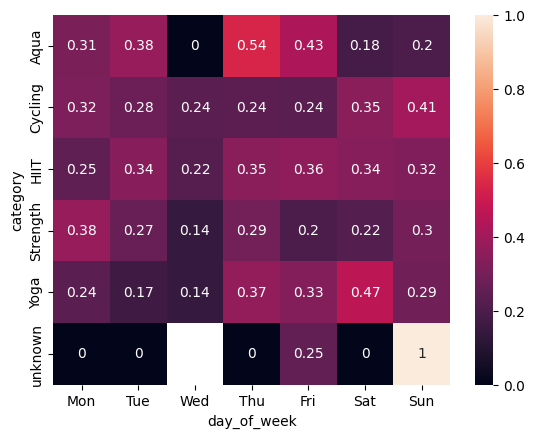

In [27]:
sns.heatmap(df.pivot_table(index='category', columns='day_of_week',
                          values='attended', aggfunc='mean',observed=False),annot=True)

### Note on Wednesday

Wednesday has the **fewest bookings** (81, versus 195-279 on other days), so its cells in the heatmap are noisy and should be read with caution.

However, its **attendance rate (~13.6%)** is also about half that of the other days (~28-33%), which is a large gap even with this sample size. The data alone cannot tell us *why*, so we only treat the day of the week as a useful predictor.


In [28]:
print(df.isna().sum())
print(df.duplicated().sum())
print(df.describe())
print(df['attended'].value_counts(normalize=True))

booking_id           0
months_as_member     0
weight              20
days_before          0
day_of_week          0
time                 0
category             0
attended             0
membership_group     0
dtype: int64
0
        booking_id  months_as_member       weight  days_before     attended
count  1500.000000       1500.000000  1480.000000  1500.000000  1500.000000
mean    750.500000         15.628667    82.610378     8.346667     0.302667
std     433.157015         12.926543    12.765859     4.077938     0.459565
min       1.000000          1.000000    55.410000     1.000000     0.000000
25%     375.750000          8.000000    73.490000     4.000000     0.000000
50%     750.500000         12.000000    80.760000     9.000000     0.000000
75%    1125.250000         19.000000    89.520000    12.000000     1.000000
max    1500.000000        148.000000   170.520000    29.000000     1.000000
attended
0    0.697333
1    0.302667
Name: proportion, dtype: float64


In [29]:
df.head()

,booking_id,months_as_member,weight,days_before,day_of_week,time,category,attended,membership_group
0,1,17,79.56,8,Wed,PM,Strength,0,"(4.0, 9.0]"
1,2,10,79.01,2,Mon,AM,HIIT,0,"(0.999, 4.0]"
2,3,16,74.53,14,Sun,AM,Strength,0,"(12.0, 29.0]"
3,4,5,86.12,10,Fri,AM,Cycling,0,"(9.0, 12.0]"
4,5,15,69.29,8,Thu,AM,HIIT,0,"(4.0, 9.0]"


In [30]:
df['weight'] = df['weight'].fillna(df['weight'].median())

In [31]:
df.isna().sum()

booking_id          0
months_as_member    0
weight              0
days_before         0
day_of_week         0
time                0
category            0
attended            0
membership_group    0
dtype: int64

# Feature Engineering

In [32]:
df['is_weekend'] = df['day_of_week'].isin(['Sat','Sun']).astype(int)
df['is_wednesday'] = (df['day_of_week'] == 'Wed').astype(int)

In [33]:
df.head()

,booking_id,months_as_member,weight,days_before,day_of_week,time,category,attended,membership_group,is_weekend,is_wednesday
0,1,17,79.56,8,Wed,PM,Strength,0,"(4.0, 9.0]",0,1
1,2,10,79.01,2,Mon,AM,HIIT,0,"(0.999, 4.0]",0,0
2,3,16,74.53,14,Sun,AM,Strength,0,"(12.0, 29.0]",1,0
3,4,5,86.12,10,Fri,AM,Cycling,0,"(9.0, 12.0]",0,0
4,5,15,69.29,8,Thu,AM,HIIT,0,"(4.0, 9.0]",0,0


In [34]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['attended', 'booking_id'])
y = df['attended']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

# Pipeline

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

# day_of_week was turned into an ordered categorical earlier;
# convert it back to plain strings so OneHotEncoder can handle it
for data in (X_train, X_test):
    data['day_of_week'] = data['day_of_week'].astype(str)

numeric_cols = ['months_as_member', 'weight', 'days_before']
categorical_cols = ['day_of_week', 'time', 'category']
binary_cols = ['is_weekend', 'is_wednesday']   # already 0/1, pass through untouched

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]), numeric_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols),
])

log_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000)),
])

baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent')),
])

# Cross-validation on the training set only; the test set stays untouched
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['f1', 'roc_auc', 'recall', 'precision']

for name, model in [('baseline', baseline), ('logistic_regression', log_reg)]:
    result = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    print(name, {m: round(result[f'test_{m}'].mean(), 3) for m in metrics})

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

baseline {'f1': np.float64(0.0), 'roc_auc': np.float64(0.5), 'recall': np.float64(0.0), 'precision': np.float64(0.0)}
logistic_regression {'f1': np.float64(0.629), 'roc_auc': np.float64(0.819), 'recall': np.float64(0.679), 'precision': np.float64(0.587)}


# Model Comparison

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, precision_score
from xgboost import XGBClassifier

# metrics to evaluate; zero_division=0 silences the precision warning
scoring = {
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
}
metrics = list(scoring)

# ratio of negative to positive class, used by XGBoost to balance the classes
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42)),
])

xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        scale_pos_weight=neg / pos, random_state=42, eval_metric='logloss')),
])

models = {
    'baseline': baseline,
    'logistic_regression': log_reg,
    'random_forest': rf,
    'xgboost': xgb,
}

for name, model in models.items():
    result = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    print(name, {m: round(result[f'test_{m}'].mean(), 3) for m in metrics})

baseline {'f1': np.float64(0.0), 'roc_auc': np.float64(0.5), 'recall': np.float64(0.0), 'precision': np.float64(0.0)}
logistic_regression {'f1': np.float64(0.629), 'roc_auc': np.float64(0.819), 'recall': np.float64(0.679), 'precision': np.float64(0.587)}
random_forest {'f1': np.float64(0.518), 'roc_auc': np.float64(0.783), 'recall': np.float64(0.456), 'precision': np.float64(0.602)}
xgboost {'f1': np.float64(0.633), 'roc_auc': np.float64(0.807), 'recall': np.float64(0.715), 'precision': np.float64(0.57)}


In [37]:
from sklearn.metrics import classification_report,confusion_matrix, roc_auc_score

threshold = 0.5 # replace with the best threshold you found 

# fit on the training set only 
log_reg.fit(X_train,y_train)

test_probs = log_reg.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= threshold).astype(int)

print('ROC-AUC:', round(roc_auc_score(y_test,test_probs),3))
print(classification_report(y_test,test_preds))
print(confusion_matrix(y_test,test_preds))


ROC-AUC: 0.82
              precision    recall  f1-score   support

           0       0.87      0.76      0.81       261
           1       0.57      0.75      0.65       114

    accuracy                           0.75       375
   macro avg       0.72      0.75      0.73       375
weighted avg       0.78      0.75      0.76       375

[[198  63]
 [ 29  85]]


In [38]:
import joblib

# refit on all data before saving, so the product uses every row
log_reg.fit(X, y)
joblib.dump({'model': log_reg, 'threshold': threshold}, 'attendance_model.joblib')

['attendance_model.joblib']

In [39]:
# Product deployment is on GitHub
# https://github.com/Tesseract-O/MLFinalProje